# Pneumatic Particle Separation in a Variable-Diameter Pulsed-Airflow Separator

## Project check-in

**Authors.** Stuart Schultz, Yogesh Panchal, Meining Miao

November 13, 2026

## 1. Introduction

Spent lithium-ion batteries are a growing source of copper, aluminum and electrode materials, and mechanical pretreatment is the first step of most recycling routes (Harper et al., 2019). After crushing and sieving, the fraction coarser than 0.25 mm consists mainly of flakes of the copper and aluminum current collectors, which must be separated from each other before either metal can be reused. Zhu et al. (2021) do this with a pulsated pneumatic separator that has a variable-diameter section. Air flows upward through a vertical column, the feed enters at the widest section, aluminum leaves with the air at the top (overflow, light product) and copper falls to the bottom (underflow, heavy product). They recover 92.08% of the copper and 96.68% of the aluminum, and for each sieve class they find an optimal air flow rate between 75 and 89 m$^3$/h.

The separation rests on the suspension velocity, the upward gas velocity at which drag balances the weight of a particle. Zhu et al. measure 2.21 m/s for aluminum and 3.93 m/s for copper foils of 5 mm $\times$ 5 mm $\times$ 0.1 mm and compare three correlations for it. Their study does not model how the pulsation, the variable diameter and the interaction between particles turn this difference into the measured recovery and grade. Li et al. (2023) give a force balance for a single particle in a pulsed, variable-diameter separator for coal, with drag, gravity, buoyancy, the pressure-gradient force and added mass.

This project builds a particle-level model of the separator of Zhu et al. on that force balance. The aim is to predict where each particle leaves the column from the geometry, the air flow and the properties of the foils, and from many particles to predict the recovery and grade of both products as functions of the air flow rate, so that the roles of the pulsation and of the variable-diameter section can be examined.

Section 2 describes the model and Section 3 lists its simplifications. Section 4 reports results at three levels, the suspension velocity of a foil, the fate of single particles over the operating range, and a multi-particle simulation with collisions that yields recovery and grade curves, which are compared with the measurements of Zhu et al. Section 5 explains how the project has progressed since the proof of concept and Section 6 lists the remaining work.

## 2. Model

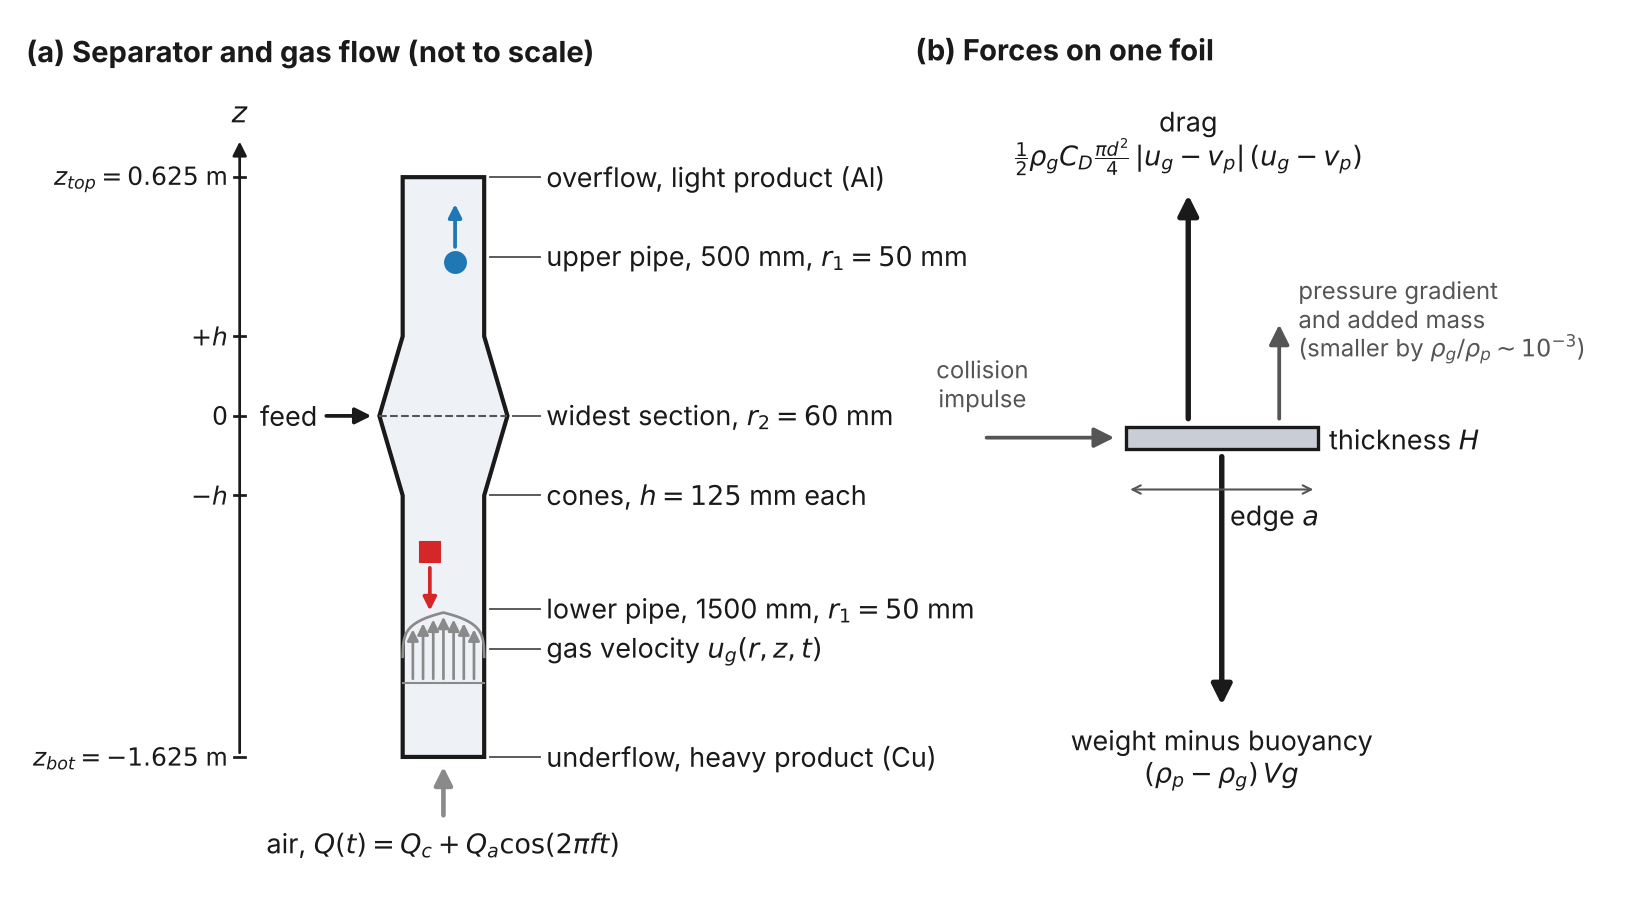

*Figure 1. (a) Separator geometry, coordinate system, outlets and gas flow. (b) Forces on one foil of edge $a$ and thickness $H$.*

### 2.1 Separator geometry

The separator consists of two straight pipes of radius $r_1 = 50$ mm joined by a double cone that widens to $r_2 = 60$ mm (Figure 1a). With $z$ measured upward from the widest section, where the feed enters, the wall radius and the cross-sectional area are

$$ r_w(z) = r_2 - (r_2 - r_1)\,\frac{|z|}{h} \quad (|z| \le h), \qquad r_w(z) = r_1 \quad (|z| > h), \qquad A(z) = \pi\, r_w(z)^2 , $$

with $h = 125$ mm for each cone, reading the 250 mm given by Zhu et al. (2021) as the height of both cones together. The upper pipe is 500 mm long and the lower pipe 1500 mm, so a particle leaves through the overflow at $z_{top} = 0.625$ m or through the underflow at $z_{bot} = -1.625$ m.

### 2.2 Gas flow

Air is treated as incompressible, so the same volume flow $Q(t)$ passes every cross-section at any instant. The blower sets a mean flow $Q_c$ and the pulsator adds a periodic part,

$$ Q(t) = Q_c + Q_a \cos(2\pi f t), \qquad 0 \le Q_a \le Q_c , $$

and continuity gives the cross-sectional mean velocity

$$ \bar u(z,t) = \frac{Q(t)}{A(z)} . $$

$Q(t)$ is prescribed, and the pressure-driven momentum balance of the air is not solved. Zhu et al. do not report the frequency or the amplitude of the pulsation. The baseline here is $f = 1$ Hz and $Q_a = 0.8\,Q_c$, and steady flow ($Q_a = 0$) is computed alongside it.

For $Q_c$ between 70 and 110 m$^3$/h the pipe Reynolds number $2 r_1 \bar u / \nu$ lies between 16,000 and 26,000, so the flow is turbulent. The single-particle model uses plug flow, $u_g = \bar u$. The multi-particle model resolves the radial position $r$ of each particle and uses the one-seventh power law of turbulent pipe flow (Schlichting and Gersten, 2017),

$$ u_g(r,z,t) = \frac{60}{49}\,\bar u(z,t)\left(1 - \frac{|r|}{r_w(z)}\right)^{1/7} , $$

where the factor 60/49 makes the profile integrate to $Q(t)$ over the cross-section. The gas velocity is taken as axial everywhere.

### 2.3 Gas acceleration seen by a particle

The unsteady fluid forces on a particle depend on the rate of change of the gas velocity as the particle experiences it. With $u_g = Q(t)/A(z)$ and a particle moving at $v_p$, the chain rule gives

$$ \frac{Du_g}{Dt} = \frac{\partial u_g}{\partial t} + v_p \frac{\partial u_g}{\partial z} = \frac{1}{A}\frac{dQ}{dt} - v_p\,\frac{Q}{A^2}\frac{dA}{dz} . $$

The first term is the pulse. The second is the effect of moving into a section of different area and vanishes in the straight pipes.

### 2.4 Force balance on a particle

Newton's second law is applied to a particle of volume $V$, density $\rho_p$ and volume-equivalent diameter $d$ (Figure 1b). Gravity, buoyancy, drag, the pressure-gradient force and added mass are retained, and the Basset history and Saffman lift forces are neglected, following Li et al. (2023),

$$ \rho_p V \frac{dv_p}{dt} = -(\rho_p - \rho_g) V g + \tfrac{1}{2} \rho_g C_D \frac{\pi d^2}{4} (u_g - v_p)\,|u_g - v_p| + \rho_g V \frac{Du_g}{Dt} + \tfrac{1}{2} \rho_g V \left( \frac{Du_g}{Dt} - \frac{dv_p}{dt} \right) . $$

Collecting the $dv_p/dt$ terms and writing $\varepsilon = \rho_p/\rho_g$ and $\phi = 3/(2\varepsilon + 1)$ gives

$$ \boxed{\; \frac{dv_p}{dt} = (\phi - 1)\, g + \frac{\phi}{2d}\, C_D\, (u_g - v_p)\,|u_g - v_p| + \phi\, \frac{Du_g}{Dt} \;} \qquad \frac{dz_p}{dt} = v_p . $$

For aluminum and copper in air $\varepsilon$ is about 2200 and 7400, so $\phi < 10^{-3}$ and the motion is governed by gravity and drag. The last term is at most $\phi\, 2\pi f Q_a / A \approx 0.02$ m/s$^2$, three orders of magnitude below $g$. It is kept in the single-particle model and dropped in the multi-particle model.

### 2.5 Drag coefficient of spheres and of foils

For a sphere, $C_D$ follows the correlation of Schiller and Naumann (1933) with the particle Reynolds number $Re = |u_g - v_p|\, d / \nu$,

$$ C_D = \frac{24}{Re} \left( 1 + 0.15\, Re^{0.687} \right) \quad (Re < 1000), \qquad C_D = 0.44 \quad (Re \ge 1000) . $$

The particles in the separator are foils. For a square foil of edge $a$ and thickness $H$, the equivalent diameter method of Zhu et al. (2021, their Eqs. 13 to 17) replaces the foil by the sphere of equal volume and corrects its drag coefficient for the shape and for the pipe wall,

$$ d = \left( \frac{6 a^2 H}{\pi} \right)^{1/3}, \qquad K = \frac{2a^2 + 4aH}{\pi d^2}, \qquad C_D = 1.55\, C\, K . $$

$K$ is the ratio of the surface area of the foil to that of the equivalent sphere, and 1.55 is the wall correction. Zhu et al. do not state the value of the resistance coefficient $C$. The value used here is $C = 1.14$, which reproduces the 2.19 and 3.98 m/s that they calculate with this method for their test foils (Section 4.1) and is close to the flat-plate value of 1.1 from Marchildon and Gauvin (1979). The thickness is $H = 0.1$ mm, that of the foils in their suspension test, and the edge $a$ is taken as the sieve size.

In a steady upward flow a particle is suspended when drag balances its weight. Setting $dv_p/dt = 0$ and $v_p = 0$ in the boxed equation gives the suspension velocity, which for a foil becomes

$$ u_s = \sqrt{\frac{2 (1 - \phi)\, g\, d}{\phi\, C_D}} \;\approx\; \sqrt{\frac{4\, g\, \rho_p H}{1.55\, C\, \rho_g\, (1 + 2H/a)}} . $$

The suspension velocity of a foil is therefore set by its thickness and density and decreases only weakly toward small sizes.

### 2.6 Many particles

The multi-particle model follows $N$ foils in a meridional plane of the column. Each foil has a position $(r_p, z_p)$ and a velocity $\mathbf v_p = (v_r, v_z)$ and obeys the balance of Section 2.4 in vector form, with the gas velocity at its own position,

$$ \frac{d\mathbf v_p}{dt} = -(1 - \phi)\, g\, \mathbf e_z + \frac{\phi}{2d}\, C_D\, |\mathbf u_g - \mathbf v_p|\, (\mathbf u_g - \mathbf v_p), \qquad \mathbf u_g = u_g(r_p, z_p, t)\, \mathbf e_z . $$

The foils interact through binary collisions. Two foils $i$ and $j$ collide during a time step if their relative motion brings their centers within $(a_i + a_j)/2$. At contact their velocities change by an impulse along the line of centers $\mathbf n$ (pointing from $j$ to $i$),

$$ \mathbf v_i' = \mathbf v_i - (1 + e)\, \frac{m_j}{m_i + m_j}\, \big[ (\mathbf v_i - \mathbf v_j) \cdot \mathbf n \big]\, \mathbf n, \qquad \mathbf v_j' = \mathbf v_j + (1 + e)\, \frac{m_i}{m_i + m_j}\, \big[ (\mathbf v_i - \mathbf v_j) \cdot \mathbf n \big]\, \mathbf n , $$

which conserves momentum and multiplies the normal relative velocity by $-e$, where $e$ is the restitution coefficient. This is the hard-sphere form of the discrete element method (Hoomans et al., 1996; Crowe et al., 2011). The soft-sphere form of Cundall and Strack (1979) resolves every contact with a spring and a dashpot, which for foils of $10^{-8}$ to $10^{-6}$ kg requires time steps near $10^{-6}$ s. The hard-sphere form applies the same momentum exchange in one step and is stable at any time step. A foil that reaches the wall is reflected with its radial velocity multiplied by $-e$. Both restitution coefficients are set to $e = 0.4$. A foil that reaches $z_{top}$ is collected in the overflow and one that reaches $z_{bot}$ in the underflow, after which it no longer moves or collides.

### 2.7 Feed, recovery and grade

The foil products of Zhu et al. contain 52.49 kg of aluminum and 64.37 kg of copper, which is 44.9% aluminum by mass, or 2.7 aluminum foils for every copper foil of the same size and thickness. Each sieve class (2 to 1.5 mm, 1.5 to 1 mm, 1 to 0.25 mm) is simulated separately, as in their experiments, with 146 aluminum and 54 copper foils whose edges are uniformly distributed within the class. The foils enter during the first two seconds near the widest section, within 25 mm of the axis and 50 mm of $z = 0$, with a lateral velocity of up to 0.5 m/s and a downward velocity of 0.2 m/s.

With $m^{top}$ and $m^{bot}$ the masses collected at the two outlets and $m^{feed}$ the mass fed,

$$ \text{Al recovery} = \frac{m_{Al}^{top}}{m_{Al}^{feed}}, \qquad \text{Al grade} = \frac{m_{Al}^{top}}{m_{Al}^{top} + m_{Cu}^{top}}, \qquad \text{Cu recovery} = \frac{m_{Cu}^{bot}}{m_{Cu}^{feed}}, \qquad \text{Cu grade} = \frac{m_{Cu}^{bot}}{m_{Cu}^{bot} + m_{Al}^{bot}} . $$

These are the four quantities plotted by Zhu et al. Material that is still in the column at the end of a run is reported separately as hold-up.

### 2.8 Numerical solution

The single-particle model is integrated with `scipy.integrate.solve_ivp` (explicit Runge-Kutta, relative tolerance $10^{-6}$) with terminal events at the two outlets. The multi-particle model advances all foils with a semi-implicit Euler step of 2 ms, about 2% of the shortest drag relaxation time $u_s / 2g \approx 0.09$ s. It is written in JAX (Bradbury et al., 2018), where `lax.scan` compiles the time loop and `vmap` runs the nine flow rates of a sweep together.

## 3. Simplifications

1. The air flow rate $Q(t)$ is prescribed and the air is incompressible. The frequency and amplitude of the pulsation are assumed because they are not reported.
2. The gas velocity is axial and follows a quasi-steady power-law profile at every height, including the cones. Entrance effects, the radial gas velocity in the cones and turbulent fluctuations are not modeled.
3. The particles do not act back on the gas (one-way coupling).
4. A foil is represented by the equivalent diameter drag law with a drag coefficient that does not depend on its orientation. All foils are 0.1 mm thick. Tumbling, bending and rotation are not modeled.
5. The multi-particle model is planar. Positions lie in one meridional plane and collisions are those of disks of diameter $a$, which overstates the collision frequency of a three-dimensional column.
6. Each run follows one batch of 200 foils with sizes uniform within the sieve class and the composition of the overall mass balance.
7. Basset history, lift and electrostatic forces are neglected.

## 4. Results

The first cell sets the properties, the geometry, the two drag laws and the single-particle model of Sections 2.1 to 2.5.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.integrate import solve_ivp
from scipy.optimize import brentq

plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

rho_g, nu, g = 1.205, 1.5e-5, 9.81            # air density (kg/m3), kinematic viscosity (m2/s), gravity (m/s2)
rho = {"Al": 2700.0, "Cu": 8960.0}            # foil densities (kg/m3)
r1, r2, h = 0.050, 0.060, 0.125               # pipe radius, widest radius, cone height (m), Zhu et al. Sec. 2.2
z_top, z_bot = h + 0.500, -(h + 1.500)        # overflow and underflow outlets (m)
H, C = 1.0e-4, 1.14                           # foil thickness (m), resistance coefficient (Section 2.5)
f_pulse, amp_pulse = 1.0, 0.8                 # baseline pulsation: frequency (Hz) and Qa/Qc
classes = {"2 ~ 1.5 mm": (1.5e-3, 2.0e-3), "1.5 ~ 1 mm": (1.0e-3, 1.5e-3), "1 ~ 0.25 mm": (0.25e-3, 1.0e-3)}
flows = np.arange(70, 111, 5)                 # mean air flow rate Qc (m3/h)
color = {"Al": "#1f77b4", "Cu": "#d62728"}

def wall(z):  return r2 - (r2 - r1) * np.minimum(np.abs(z), h) / h           # wall radius r_w(z)
def area(z):  return np.pi * wall(z) ** 2
def dA_dz(z): return np.where(np.abs(z) < h, -2 * np.pi * wall(z) * (r2 - r1) / h * np.sign(z), 0.0)

def cd_sphere(Re):                            # Schiller and Naumann
    Re = np.maximum(Re, 1e-9)
    return np.where(Re < 1000, 24 / Re * (1 + 0.15 * Re**0.687), 0.44)

def foil(a):                                  # equivalent diameter and C_D of an a x a x H foil (Zhu et al., Eqs. 13 to 16)
    d = (6 * a**2 * H / np.pi) ** (1 / 3)
    return d, 1.55 * C * (2 * a**2 + 4 * a * H) / (np.pi * d**2)

def particle(shape, a):                       # d and C_D(Re) of a sphere of diameter a or a foil of edge a
    if shape == "sphere":
        return a, cd_sphere
    d, cd = foil(a)
    return d, lambda Re: cd

def phi_of(metal): return 3 / (2 * rho[metal] / rho_g + 1)

def suspension_velocity(shape, a, metal):     # gas velocity at which drag balances weight
    d, cd = particle(shape, a)
    return brentq(lambda u: phi_of(metal) / (2 * d) * cd(u * d / nu) * u**2 - (1 - phi_of(metal)) * g, 1e-3, 100.0)

def rhs(t, y, d, cd, phi, Qc, Qa):            # boxed equation of Section 2.4 with plug flow u_g = Q/A
    z, v = y
    w = 2 * np.pi * f_pulse
    Q, dQ, A = Qc + Qa * np.cos(w * t), -w * Qa * np.sin(w * t), area(z)
    u = Q / A
    Du = dQ / A - v * Q / A**2 * dA_dz(z)                                    # Section 2.3
    return [v, (phi - 1) * g + phi / (2 * d) * cd(abs(u - v) * d / nu) * (u - v) * abs(u - v) + phi * Du]

def simulate(shape, a, metal, Q, amp, T=30.0):  # one particle released at rest at z = 0; stops at an outlet
    d, cd = particle(shape, a)
    top = lambda t, y, *p: y[0] - z_top
    bot = lambda t, y, *p: y[0] - z_bot
    top.terminal = bot.terminal = True
    sol = solve_ivp(rhs, (0, T), [0.0, 0.0], args=(d, cd, phi_of(metal), Q / 3600, amp * Q / 3600),
                    events=[top, bot], max_step=0.01, rtol=1e-6, atol=1e-9)
    fate = "top" if sol.t_events[0].size else "bottom" if sol.t_events[1].size else "held"
    return sol.t, sol.y[0], fate

### 4.1 Suspension velocity

Table 1 compares the suspension velocity of a solid sphere and of a foil with the measurement of Zhu et al., and with the gas velocity available in the column.

In [2]:
sizes = {"0.625 mm": 0.625e-3, "1.25 mm": 1.25e-3, "1.75 mm": 1.75e-3, "5 mm": 5.0e-3}
rows = {(shape, metal): [suspension_velocity(shape, a, metal) for a in sizes.values()]
        for shape in ("sphere", "foil") for metal in ("Al", "Cu")}
rows[("measured (Zhu et al.)", "Al")] = [np.nan] * 3 + [2.21]
rows[("measured (Zhu et al.)", "Cu")] = [np.nan] * 3 + [3.93]
table1 = pd.DataFrame(rows, index=pd.Index(sizes.keys(), name="size")).T
print("Table 1. Suspension velocity (m/s) of a sphere of diameter a and of a foil of edge a and thickness 0.1 mm")
display(table1.style.format(precision=2, na_rep=""))
u = lambda Q, z: Q / 3600 / area(z)
print(f"Mean gas velocity at 70 to 110 m3/h: {u(70, h):.2f} to {u(110, h):.2f} m/s in the pipes, "
      f"{u(70, 0):.2f} to {u(110, 0):.2f} m/s in the widest section")

Table 1. Suspension velocity (m/s) of a sphere of diameter a and of a foil of edge a and thickness 0.1 mm


Mean gas velocity at 70 to 110 m3/h: 2.48 to 3.89 m/s in the pipes, 1.72 to 2.70 m/s in the widest section


The foil law gives 2.19 m/s for aluminum and 3.98 m/s for copper at the size used in the suspension test, within 1.3% of the measured 2.21 and 3.93 m/s. For the three sieve classes it gives 1.9 to 2.1 m/s for aluminum and 3.5 to 3.9 m/s for copper, values that bracket the mean gas velocity in the pipes. A solid sphere of the same size needs 4.8 to 19.7 m/s, more than the mean gas velocity at any flow rate in the operating range, so a sphere cannot stand in for a foil. The foil drag law is used in all simulations that follow.

### 4.2 Single particles over the operating range

A foil of the mid-size of each sieve class is released at rest at the widest section and followed until it reaches an outlet, for nine flow rates in steady and in pulsed flow. Table 2 lists the outcome of all 108 simulations, the outlet reached and the time needed, or "held" if the foil is still in the column after 30 s. Figure 2 shows the trajectories of the 1.5 to 1 mm class at three flow rates.

In [3]:
mid = {"2 ~ 1.5 mm": 1.75e-3, "1.5 ~ 1 mm": 1.25e-3, "1 ~ 0.25 mm": 0.625e-3}
rows = {}
for mode, A in (("steady", 0.0), ("pulsed", amp_pulse)):
    for name, a in mid.items():
        for metal in ("Al", "Cu"):
            out = [simulate("foil", a, metal, Q, A) for Q in flows]
            rows[(mode, name, metal)] = ["held" if fate == "held" else f"{fate} {t[-1]:.1f} s" for t, z, fate in out]
table2 = pd.DataFrame(rows, index=pd.Index(flows, name="Qc (m3/h)")).T
shade = lambda v: "background-color: " + ("#dbe9f6" if v.startswith("top") else "#f9dcdc" if v.startswith("bottom") else "#e4e4e4")
print("Table 2. Outlet reached by a single foil and time to reach it (top = overflow, bottom = underflow)")
display(table2.style.map(shade))

Table 2. Outlet reached by a single foil and time to reach it (top = overflow, bottom = underflow)


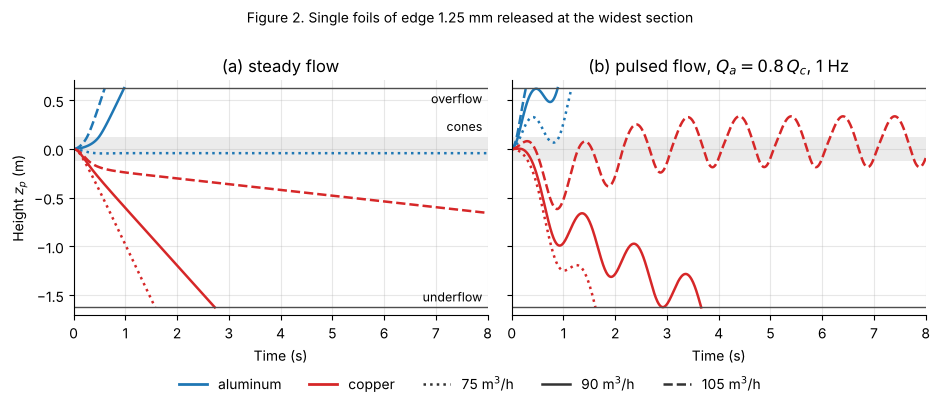

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.7), sharey=True)
styles = {75: ":", 90: "-", 105: "--"}
for k, (title, A) in enumerate((("(a) steady flow", 0.0), ("(b) pulsed flow, $Q_a = 0.8\\,Q_c$, 1 Hz", amp_pulse))):
    ax[k].axhspan(-h, h, color="0.92", lw=0)
    for Q, ls in styles.items():
        for metal in ("Al", "Cu"):
            t, z, fate = simulate("foil", 1.25e-3, metal, Q, A, T=8.0)
            ax[k].plot(t, z, ls, color=color[metal], lw=1.8)
    ax[k].axhline(z_top, color="0.3", lw=1); ax[k].axhline(z_bot, color="0.3", lw=1)
    ax[k].set(title=title, xlabel="Time (s)", xlim=(0, 8), ylim=(z_bot - 0.08, z_top + 0.08))
ax[0].set_ylabel("Height $z_p$ (m)")
ax[0].text(7.9, z_top - 0.03, "overflow", ha="right", va="top", fontsize=9); ax[0].text(7.9, z_bot + 0.03, "underflow", ha="right", va="bottom", fontsize=9)
ax[0].text(7.9, h + 0.03, "cones", ha="right", va="bottom", fontsize=9)
handles = [Line2D([], [], color=color["Al"], lw=2, label="aluminum"), Line2D([], [], color=color["Cu"], lw=2, label="copper")]
handles += [Line2D([], [], color="0.2", ls=ls, lw=1.8, label=f"{Q} m$^3$/h") for Q, ls in styles.items()]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Figure 2. Single foils of edge 1.25 mm released at the widest section", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

In steady flow the aluminum foil reaches the overflow only above a threshold flow rate, which is 90, 85 and 80 m$^3$/h for the three classes. Below the threshold the foil is held in the lower cone, at the height where the gas velocity equals its suspension velocity (dotted blue line in Figure 2a). This position is stable because the gas velocity increases downward in the lower cone. The copper foil reaches the underflow up to 105 m$^3$/h (95 m$^3$/h for the finest class), more slowly as the flow rate increases, and is held above that. Steady flow therefore separates the two metals between 90 and 105 m$^3$/h for the coarsest class, 85 and 105 m$^3$/h for the middle class and 80 and 95 m$^3$/h for the finest.

Pulsation releases the held aluminum, which then reaches the overflow at every flow rate. It also lowers the limit for copper to 95 m$^3$/h (90 m$^3$/h for the finest class), above which copper is held or carried to the overflow. The separation window in pulsed flow is 70 to 95 m$^3$/h (70 to 90 m$^3$/h for the finest class). In both modes the thresholds decrease with particle size, in the same direction as the optimal flow rates of 89, 84 and 75 m$^3$/h reported by Zhu et al.

### 4.3 Many particles with collisions

The next cell is the multi-particle model of Sections 2.6 and 2.7. One call of `sweep` follows 200 foils for 20 s at each of the nine flow rates. The check at the end releases one copper foil on the axis in steady flow and compares its final velocity with the centerline gas velocity minus the suspension velocity.

In [5]:
import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)

dt, T_run, stride = 2.0e-3, 20.0, 100         # time step (s), simulated time (s), steps between stored frames
e_rest = 0.4                                  # restitution coefficient, particle-particle and particle-wall
x_al = 52.49 / (52.49 + 64.37)                # aluminum mass fraction of the foils (Zhu et al.)
n_al = round(200 * (x_al / rho["Al"]) / (x_al / rho["Al"] + (1 - x_al) / rho["Cu"]))
n_cu = 200 - n_al

def wall_j(z): return r2 - (r2 - r1) * jnp.minimum(jnp.abs(z), h) / h

def gas_velocity(r, z, t, Qc, Qa):            # one-seventh power law, Section 2.2
    R = wall_j(z)
    Q = Qc + Qa * jnp.cos(2 * jnp.pi * f_pulse * t)
    return 60 / 49 * Q / (jnp.pi * R**2) * jnp.clip(1 - jnp.abs(r) / R, 0.0, 1.0) ** (1 / 7)

def collision_kick(r, z, vr, vz, rad, mass, active):
    """Velocity change of every foil from hard-sphere impulses with all foils it touches within dt (Section 2.6)."""
    dx, dz = r[:, None] - r[None, :], z[:, None] - z[None, :]
    dvx, dvz = vr[:, None] - vr[None, :], vz[:, None] - vz[None, :]
    S = rad[:, None] + rad[None, :]
    b = dx * dvx + dz * dvz                                               # negative when the pair approaches
    w2 = dvx**2 + dvz**2 + 1e-30
    c = dx**2 + dz**2 - S**2
    disc = b**2 - w2 * c
    tc = jnp.where(c < 0, 0.0, (-b - jnp.sqrt(jnp.maximum(disc, 0.0))) / w2)   # time of first contact
    hit = active[:, None] & active[None, :] & (b < 0) & (disc > 0) & (tc <= dt) & ~jnp.eye(r.shape[0], dtype=bool)
    nx, nz = dx + dvx * tc, dz + dvz * tc                                 # line of centers at contact
    J = jnp.where(hit, -(1 + e_rest) * (dvx * nx + dvz * nz) / (nx**2 + nz**2 + 1e-30) * mass[None, :] / (mass[:, None] + mass[None, :]), 0.0)
    return jnp.sum(J * nx, axis=1), jnp.sum(J * nz, axis=1)

def run(p, Qc, Qa):
    """Follows the foils in p for T_run seconds. Returns the final state and frames of (r, z, status)."""
    def step(state, k):
        r, z, vr, vz, status = state
        t = k * dt
        active = (status == 0) & (t >= p["t_feed"])                       # fed and not yet collected
        kr, kz = collision_kick(r, z, vr, vz, p["rad"], p["mass"], active)
        vr, vz = vr + kr, vz + kz
        sr, sz = -vr, gas_velocity(r, z, t, Qc, Qa) - vz                  # slip velocity
        s = jnp.sqrt(sr**2 + sz**2)
        vr_n, vz_n = vr + p["beta"] * s * sr * dt, vz + (p["beta"] * s * sz - p["grav"]) * dt
        r_n, z_n = r + vr_n * dt, z + vz_n * dt
        R = wall_j(z_n) - p["rad"]                                        # wall reflection
        vr_n = jnp.where(jnp.abs(r_n) > R, -e_rest * jnp.abs(vr_n) * jnp.sign(r_n), vr_n)
        r_n = jnp.clip(r_n, -R, R)
        r, z, vr, vz = [jnp.where(active, new, old) for new, old in ((r_n, r), (z_n, z), (vr_n, vr), (vz_n, vz))]
        status = jnp.where(active & (z >= z_top), 1, jnp.where(active & (z <= z_bot), -1, status))
        return (r, z, vr, vz, status), None
    def frame(state, i):
        state, _ = jax.lax.scan(step, state, i * stride + jnp.arange(stride))
        return state, (state[0], state[1], state[4])
    start = (p["r0"], p["z0"], p["vr0"], p["vz0"], jnp.zeros(p["r0"].shape[0], dtype=jnp.int32))
    return jax.lax.scan(frame, start, jnp.arange(int(round(T_run / dt)) // stride))

sweep = jax.jit(jax.vmap(run, in_axes=(None, 0, 0)))                      # all flow rates of one sweep together

def make_feed(lo, hi, n_al=n_al, n_cu=n_cu, seed=0):
    rng = np.random.default_rng(seed)
    n = n_al + n_cu
    is_al = np.arange(n) < n_al
    a = rng.uniform(lo, hi, n)
    d, cd = foil(a)
    rho_p = np.where(is_al, rho["Al"], rho["Cu"])
    phi = 3 / (2 * rho_p / rho_g + 1)
    p = dict(beta=phi * cd / (2 * d), grav=(1 - phi) * g, rad=a / 2, mass=rho_p * a**2 * H, t_feed=rng.uniform(0, 2, n),
             r0=rng.uniform(-0.025, 0.025, n), z0=rng.uniform(-0.05, 0.05, n), vr0=rng.uniform(-0.5, 0.5, n), vz0=np.full(n, -0.2))
    return {k: jnp.asarray(v) for k, v in p.items()}, is_al

# check: one copper foil on the axis in steady flow at 80 m3/h
p1, _ = make_feed(1.25e-3, 1.25e-3, n_al=0, n_cu=1)
p1.update(r0=jnp.zeros(1), vr0=jnp.zeros(1), t_feed=jnp.zeros(1))
state, _ = jax.jit(run)(p1, 80 / 3600, 0.0)
print(f"Check: copper foil on the axis leaves at v_z = {float(state[3][0]):+.3f} m/s; "
      f"centerline gas velocity minus suspension velocity = {60 / 49 * 80 / 3600 / area(h) - suspension_velocity('foil', 1.25e-3, 'Cu'):+.3f} m/s")

Check: copper foil on the axis leaves at v_z = -0.308 m/s; centerline gas velocity minus suspension velocity = -0.308 m/s


In [6]:
def split(p, is_al, status):                  # recovery, grade and hold-up (%) from the outlet reached by each foil
    m = np.asarray(p["mass"])
    top, bot, held = status == 1, status == -1, status == 0
    pct = lambda x, y: 100 * x.sum() / y.sum() if y.sum() > 0 else np.nan
    return {"Al recovery": pct(m[is_al & top], m[is_al]), "Cu recovery": pct(m[~is_al & bot], m[~is_al]),
            "Al grade": pct(m[is_al & top], m[top]), "Cu grade": pct(m[~is_al & bot], m[bot]), "held": pct(m[held], m)}

results, frames = {}, {}
for name, (lo, hi) in classes.items():
    p, is_al = make_feed(lo, hi)
    for mode, A in (("steady", 0.0), ("pulsed", amp_pulse)):
        state, fr = sweep(p, jnp.asarray(flows) / 3600, A * jnp.asarray(flows) / 3600)
        results[mode, name] = pd.DataFrame([split(p, is_al, s) for s in np.asarray(state[4])], index=flows)
        frames[mode, name] = [np.asarray(x) for x in fr] + [is_al, np.asarray(p["t_feed"])]

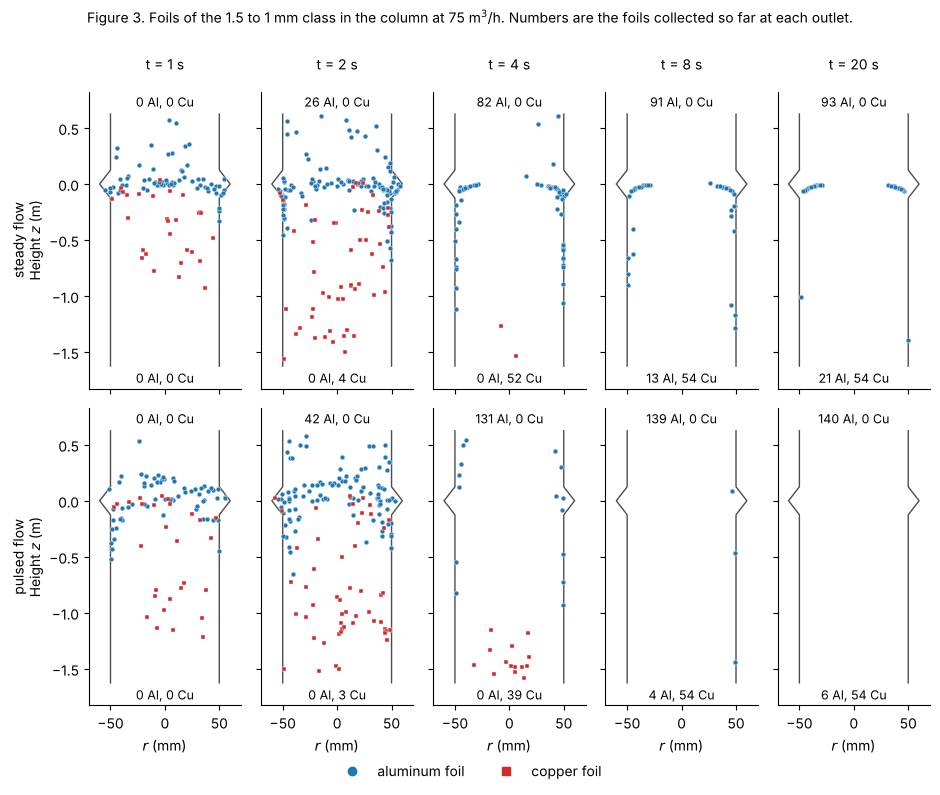

In [7]:
def snapshots(axs, mode, name, Q, times):
    r, z, status, is_al, t_feed = frames[mode, name]
    i = list(flows).index(Q)
    zz = np.linspace(z_bot, z_top, 300)
    for a, t in zip(axs, times):
        k = int(round(t / (stride * dt))) - 1
        a.plot(1e3 * wall(zz), zz, color="0.3", lw=1); a.plot(-1e3 * wall(zz), zz, color="0.3", lw=1)
        inside = (status[i, k] == 0) & (t_feed <= t)
        for metal, sel, mk in (("Al", is_al, "o"), ("Cu", ~is_al, "s")):
            a.plot(1e3 * r[i, k][inside & sel], z[i, k][inside & sel], mk, ms=3.5, color=color[metal], mec="white", mew=0.3)
        top, bot = status[i, k] == 1, status[i, k] == -1
        a.text(0, z_top + 0.04, f"{(top & is_al).sum()} Al, {(top & ~is_al).sum()} Cu", ha="center", va="bottom", fontsize=9)
        a.text(0, z_bot - 0.04, f"{(bot & is_al).sum()} Al, {(bot & ~is_al).sum()} Cu", ha="center", va="top", fontsize=9)
        a.set(xlim=(-70, 70), ylim=(z_bot - 0.2, z_top + 0.2), xticks=[-50, 0, 50])
        a.grid(False)

times = (1, 2, 4, 8, 20)
fig, ax = plt.subplots(2, 5, figsize=(9.5, 7.6), sharex=True, sharey=True)
for row, mode in enumerate(("steady", "pulsed")):
    snapshots(ax[row], mode, "1.5 ~ 1 mm", 75, times)
    ax[row, 0].set_ylabel(f"{mode} flow\nHeight $z$ (m)")
for a, t in zip(ax[0], times): a.set_title(f"t = {t} s", fontsize=10, pad=16)
for a in ax[1]: a.set_xlabel("$r$ (mm)")
handles = [Line2D([], [], marker="o", ls="", color=color["Al"], label="aluminum foil"), Line2D([], [], marker="s", ls="", color=color["Cu"], label="copper foil")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.03))
fig.suptitle("Figure 3. Foils of the 1.5 to 1 mm class in the column at 75 m$^3$/h. Numbers are the foils collected so far at each outlet.", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

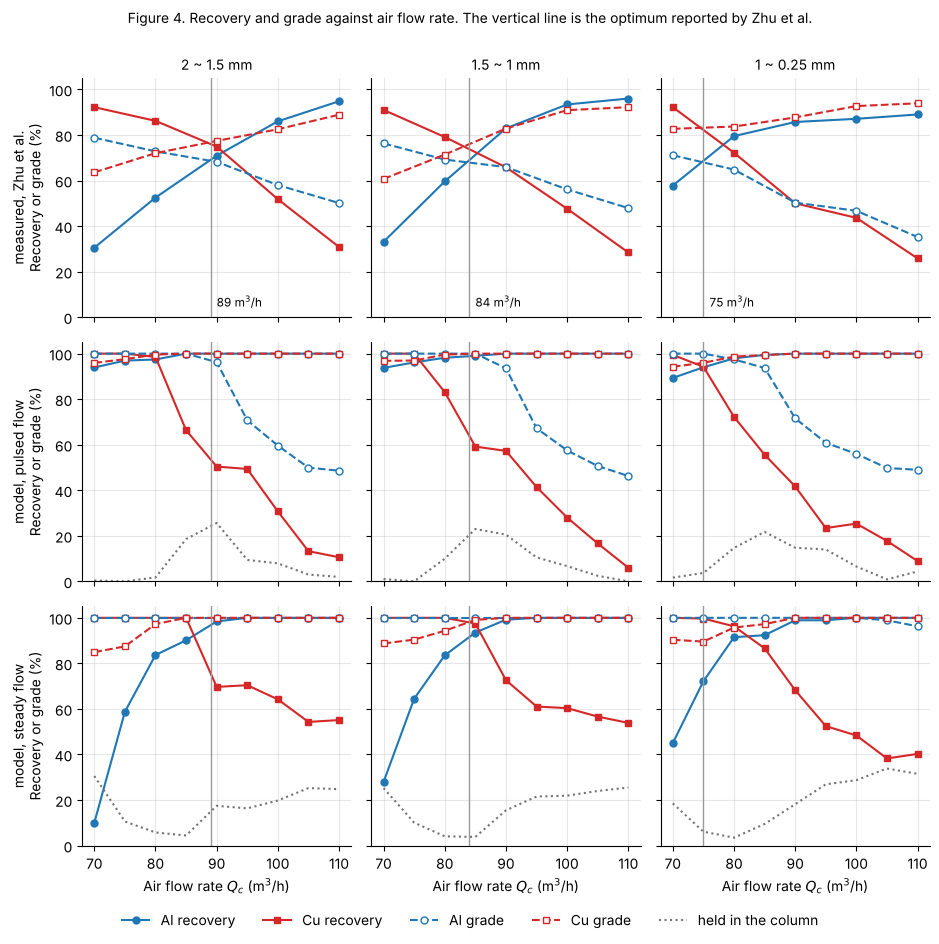

Table 3. Flow rate with the highest sum of the two recoveries, and the recoveries there


,optimum reported by Zhu et al.,measured,"model, pulsed","model, steady"
size class,,,,
2 ~ 1.5 mm,89,"90 m3/h (Al 71%, Cu 75%)","75 m3/h (Al 97%, Cu 100%)","85 m3/h (Al 90%, Cu 100%)"
1.5 ~ 1 mm,84,"90 m3/h (Al 83%, Cu 66%)","75 m3/h (Al 96%, Cu 100%)","85 m3/h (Al 94%, Cu 97%)"
1 ~ 0.25 mm,75,"80 m3/h (Al 80%, Cu 72%)","70 m3/h (Al 89%, Cu 99%)","80 m3/h (Al 91%, Cu 96%)"


In [8]:
zhu_Q = [70, 80, 90, 100, 110]                # read from Fig. 4 of Zhu et al. (2021), reading error about 1 point
zhu = {"2 ~ 1.5 mm":  {"Al recovery": [30.5, 52.5, 70.9, 86.0, 94.8], "Cu recovery": [92.2, 86.2, 74.9, 51.8, 30.8],
                       "Al grade": [78.8, 72.8, 68.2, 58.0, 50.1], "Cu grade": [63.6, 72.0, 77.4, 82.5, 88.9]},
       "1.5 ~ 1 mm":  {"Al recovery": [33.1, 59.6, 82.9, 93.4, 96.0], "Cu recovery": [91.0, 79.1, 65.8, 47.6, 28.4],
                       "Al grade": [76.3, 69.2, 65.9, 56.1, 47.9], "Cu grade": [60.7, 71.4, 82.8, 90.9, 92.2]},
       "1 ~ 0.25 mm": {"Al recovery": [57.8, 79.5, 85.7, 87.1, 89.0], "Cu recovery": [92.2, 72.2, 50.0, 43.6, 25.8],
                       "Al grade": [71.1, 64.8, 50.3, 46.7, 35.2], "Cu grade": [82.7, 83.7, 87.7, 92.7, 93.9]}}
zhu_opt = {"2 ~ 1.5 mm": 89, "1.5 ~ 1 mm": 84, "1 ~ 0.25 mm": 75}
look = {"Al recovery": dict(color=color["Al"], ls="-", marker="o"), "Cu recovery": dict(color=color["Cu"], ls="-", marker="s"),
        "Al grade": dict(color=color["Al"], ls="--", marker="o", mfc="white"), "Cu grade": dict(color=color["Cu"], ls="--", marker="s", mfc="white")}

fig, ax = plt.subplots(3, 3, figsize=(9.5, 9.0), sharex=True, sharey=True)
for j, name in enumerate(classes):
    data = [pd.DataFrame(zhu[name], index=zhu_Q), results["pulsed", name], results["steady", name]]
    for i, df in enumerate(data):
        for key, kw in look.items():
            ax[i, j].plot(df.index, df[key], lw=1.5, ms=5, **kw)
        if i > 0:
            ax[i, j].plot(df.index, df["held"], color="0.45", ls=":", lw=1.5)
        ax[i, j].axvline(zhu_opt[name], color="0.6", lw=1)
    ax[0, j].set_title(name, fontsize=10)
    ax[0, j].text(zhu_opt[name] + 1, 3, f"{zhu_opt[name]} m$^3$/h", fontsize=8.5, va="bottom")
    ax[2, j].set_xlabel("Air flow rate $Q_c$ (m$^3$/h)")
for i, label in enumerate(("measured, Zhu et al.", "model, pulsed flow", "model, steady flow")):
    ax[i, 0].set_ylabel(f"{label}\nRecovery or grade (%)")
ax[0, 0].set(ylim=(0, 105), xticks=range(70, 111, 10))
handles = [Line2D([], [], lw=1.5, ms=5, label=key, **kw) for key, kw in look.items()] + [Line2D([], [], color="0.45", ls=":", label="held in the column")]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.035))
fig.suptitle("Figure 4. Recovery and grade against air flow rate. The vertical line is the optimum reported by Zhu et al.", y=1.0, fontsize=10)
plt.tight_layout()
plt.show()

best = lambda df: (df["Al recovery"] + df["Cu recovery"]).idxmax()
rows = []
for name in classes:
    row = {"size class": name, "optimum reported by Zhu et al.": zhu_opt[name]}
    for label, df in (("measured", pd.DataFrame(zhu[name], index=zhu_Q)), ("model, pulsed", results["pulsed", name]), ("model, steady", results["steady", name])):
        Q = best(df)
        row[label] = f"{Q} m3/h  (Al {df.loc[Q, 'Al recovery']:.0f}%, Cu {df.loc[Q, 'Cu recovery']:.0f}%)"
    rows.append(row)
print("Table 3. Flow rate with the highest sum of the two recoveries, and the recoveries there")
display(pd.DataFrame(rows).set_index("size class"))

Figure 3 shows what the two flow modes do to the same feed at 75 m$^3$/h. Copper falls to the underflow in both. In steady flow about two thirds of the aluminum reaches the overflow. The rest either collects just below the widest section, where the gas velocity equals its suspension velocity, or slides down along the wall, where the gas is slow, and is lost to the underflow. In pulsed flow almost all of the aluminum leaves through the overflow within a few seconds.

Figure 4 compares the recovery and grade of the model with the measurements of Zhu et al., which were read from their Figure 4 with a reading error of about one point. In pulsed flow all four curves of the model move in the measured direction as the flow rate increases. Aluminum recovery and copper grade rise, and copper recovery and aluminum grade fall because copper is carried into the overflow. In steady flow the aluminum recovery rises from between 10 and 45% at 70 m$^3$/h to 100%, as steeply as in the measurements, but no copper reaches the overflow, so the aluminum grade stays at 100% and the copper that does not fall is held in the column. Copper is carried over at lower flow rates than in Table 2 because foils near the axis see a gas velocity up to 22% above the mean. The flow rate with the highest combined recovery (Table 3) is 80 to 85 m$^3$/h in steady flow and 70 to 75 m$^3$/h in pulsed flow, against the optimum of 75 to 89 m$^3$/h reported by Zhu et al., and it is lowest for the finest class, as in the experiment. No parameter was fitted to these curves.

The model differs from the experiment in two ways. First, it separates more sharply. At its best flow rate both recoveries are about 90% or higher, against 66 to 83% measured, and its grades reach 100%. All foils in the model have the same thickness and an ideal shape, whereas crushed fragments vary in thickness, are bent and may carry residual coating, which spreads their suspension velocities. Second, the pulsed model already recovers about 90% of the aluminum at 70 m$^3$/h, where 30 to 58% is measured, and the steady model is closer there. The amplitude of the pulsation in the experiment is not known, and the two modes computed here bracket the measured behavior.

Up to a third of the feed is still in the column after 20 s. It is copper in and below the lower cone at intermediate and high flow rates and, in steady flow, aluminum at low flow rates. This hold-up is a consequence of the variable diameter (Section 4.2). The model is dilute and has no mechanism that discharges it, so it is reported separately and not assigned to a product.

Each curve is one realization of 200 foils. For the 2 to 1.5 mm class the runs were repeated with two other random feeds, with half the time step and with a restitution coefficient of 0.8 (not shown). Single points changed by up to about 10 points for aluminum and 20 points for copper, of which there are only 54 foils per run, and the shapes of the curves did not change. A restitution coefficient of 0.1 raised the copper recovery at high flow rates by 10 to 30 points, because less copper was held.

## 5. Progress since the proof of concept

The proof of concept solved the one-dimensional force balance for spherical particles in a prescribed plug flow. Particles were followed for a fixed time, and the result was the difference in velocity and displacement between pulsed and steady flow for aluminum and copper populations. The work since then has added the following.

1. **Foil drag law.** The sphere drag law has been replaced by the equivalent diameter law for foils and checked against the measured suspension velocities (Table 1). This moved the suspension velocities from 5 to 20 m/s into the range of the gas velocity in the separator, which is the precondition for predicting recovery.
2. **Outlet-based classification.** Trajectories now end at the overflow or the underflow through event detection, so every particle has a definite fate. Table 2 summarizes all single-particle simulations over the operating range.
3. **Multi-particle model.** Two hundred foils per run move in a radially varying gas velocity, collide with each other and with the wall, and are collected at the outlets. The model is vectorized in JAX and the nine flow rates of a sweep are simulated together.
4. **Recovery and grade curves.** The model now produces the quantities measured by Zhu et al. and is compared with their data for the three sieve classes (Figure 4, Table 3).
5. **Roles of the pulsation and of the variable diameter.** The simulations show that the lower cone holds particles whose suspension velocity lies between the gas velocities of the widest section and of the pipe, and that pulsation releases them.

## 6. Remaining work

1. **Variability of the feed.** The model separates more sharply than the experiment. Distributions of foil thickness and shape are the first extension.
2. **Pulsation parameters.** The frequency and $Q_a/Q_c$ are not reported. They will be varied systematically, and $Q_a/Q_c$ will be estimated by fitting the measured recoveries.
3. **Turbulent dispersion.** A random-walk model of the velocity fluctuations will let particles sample different radii, which also affects the hold-up.
4. **Hold-up.** A continuous feed and longer runs are needed to decide where held material finally leaves. At high loading the effect of the particles on the gas has to be included.
5. **Collisions.** The collisions will be extended to three dimensions, and the restitution coefficient, to which the copper recovery at high flow rates is sensitive, needs a measured value.
6. **Coupled air flow.** $Q(t)$ will be obtained from the pressure-driven momentum balance of the air instead of being prescribed.

## 7. References

Bradbury, J.; Frostig, R.; Hawkins, P.; Johnson, M. J.; Leary, C.; Maclaurin, D.; Necula, G.; Paszke, A.; VanderPlas, J.; Wanderman-Milne, S.; Zhang, Q. *JAX: Composable Transformations of Python+NumPy Programs*, 2018. http://github.com/jax-ml/jax.

Crowe, C. T.; Schwarzkopf, J. D.; Sommerfeld, M.; Tsuji, Y. *Multiphase Flows with Droplets and Particles*, 2nd ed.; CRC Press, 2011.

Cundall, P. A.; Strack, O. D. L. A Discrete Numerical Model for Granular Assemblies. *Géotechnique* 1979, 29 (1), 47–65.

Harper, G.; Sommerville, R.; Kendrick, E.; et al. Recycling Lithium-Ion Batteries from Electric Vehicles. *Nature* 2019, 575, 75–86.

Hoomans, B. P. B.; Kuipers, J. A. M.; Briels, W. J.; van Swaaij, W. P. M. Discrete Particle Simulation of Bubble and Slug Formation in a Two-Dimensional Gas-Fluidised Bed: A Hard-Sphere Approach. *Chemical Engineering Science* 1996, 51 (1), 99–118.

Li, D.; Wang, L.; Wei, L.; Qu, Q.; Wang, J. A Study of the Dynamic Mechanism in Low-Rank Coal Separation with Varying-Diameter Pulsed Airflow Separator. *Coal Preparation Technology* 2023, 51 (2), 9–13. DOI: 10.16447/j.cnki.cpt.2023.02.002.

Marchildon, E. K.; Gauvin, W. H. Effects of Acceleration, Deceleration and Particle Shape on Single-Particle Drag Coefficients in Still Air. *AIChE Journal* 1979, 25 (6), 938–948.

Schiller, L.; Naumann, A. Über die grundlegenden Berechnungen bei der Schwerkraftaufbereitung. *Zeitschrift des Vereines Deutscher Ingenieure* 1933, 77, 318–320.

Schlichting, H.; Gersten, K. *Boundary-Layer Theory*, 9th ed.; Springer, 2017.

Zhu, X.; Zhang, C.; Feng, P.; Yang, X.; Yang, X. A Novel Pulsated Pneumatic Separation with Variable-Diameter Structure and Its Application in the Recycling Spent Lithium-Ion Batteries. *Waste Management* 2021, 131, 20–30. DOI: 10.1016/j.wasman.2021.05.027.

**Methods and their sources**

| Method | Used in | Source |
|---|---|---|
| Separator geometry, feed composition, sieve classes, measured recovery and grade | Sections 2.1, 2.7, 4.3 | Zhu et al. (2021) |
| Particle force balance with pressure-gradient force and added mass | Sections 2.3, 2.4 | Li et al. (2023); Crowe et al. (2011) |
| Drag coefficient of a sphere | Section 2.5 | Schiller and Naumann (1933) |
| Equivalent diameter drag law of a foil, wall correction | Section 2.5 | Zhu et al. (2021); Marchildon and Gauvin (1979) |
| One-seventh power-law velocity profile, factor 60/49 | Section 2.2 | Schlichting and Gersten (2017) |
| Discrete element method, soft-sphere contact | Section 2.6 | Cundall and Strack (1979) |
| Hard-sphere collision with restitution | Section 2.6 | Hoomans et al. (1996); Crowe et al. (2011) |
| Runge-Kutta integration with event detection | Section 2.8 | SciPy `solve_ivp` |
| Vectorized time stepping (`vmap`, `lax.scan`) | Section 2.8 | Bradbury et al. (2018) |

## 8. Contributions

**Stuart Schultz** developed the multi-particle simulation in JAX, including the power-law gas velocity profile, the distributed feed, the particle collisions and the sweep over flow rates.

**Yogesh Panchal** implemented the foil drag law and its check against the measured suspension velocities, the outlet-based classification with the single-particle summary, and the evaluation of recovery and grade against the data of Zhu et al.

**Meining Miao** developed the literature-based feed composition and sieve classes used in all simulations.

All three authors contributed to the literature review, the preparation of the notebook and the interpretation of the results.